# KeySense AI — Audio Processing (Fixed)

This notebook processes the recordings in **`data/session2/` only**. It writes new results under **`dataset/session2/`** and does not overwrite your existing Session 1 dataset.

Expected input naming: one file per key, e.g. `A.wav`, `B.mp3`, … `Z.wav`. Each file may contain multiple presses of that key.

Run cells from top to bottom. First inspect the sample recording and detector settings, then run the batch-processing cell.

In [1]:
%pip install numpy matplotlib librosa sounddevice soundfile scipy scikit-learn tensorflow noisereduce pandas pillow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import csv
import re
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import librosa
import librosa.display
import soundfile as sf
import noisereduce as nr
import pandas as pd
from IPython.display import Audio, display

# Session 2 only — keep Session 1 and the old dataset untouched.
DATA_DIR = Path("./data/session2")
SESSION_OUTPUT = Path("./dataset/session2")
DETECTED_ROOT = SESSION_OUTPUT / "detected"
SPECTROGRAM_ROOT = SESSION_OUTPUT / "spectrogram_images"
MANIFEST_PATH = SESSION_OUTPUT / "manifest.csv"

SAMPLE_RATE = 40000
NOISE_SECONDS = 0.8
NOISE_REDUCTION = 1
PRE_ROLL = 0.10
POST_ROLL = 0.18
MERGE_GAP = 0.12
MIN_EVENT_DURATION = 0.025
THRESHOLD_MULTIPLIER = 3.0

AUDIO_EXTENSIONS = {".wav", ".mp3", ".flac", ".m4a", ".ogg", ".aiff", ".aif"}

SESSION_OUTPUT.mkdir(parents=True, exist_ok=True)
DETECTED_ROOT.mkdir(parents=True, exist_ok=True)
SPECTROGRAM_ROOT.mkdir(parents=True, exist_ok=True)

if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_DIR.resolve()}. Check that your project has data/session2."
    )

audio_files = sorted(
    p for p in DATA_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in AUDIO_EXTENSIONS
)

print(f"Found {len(audio_files)} audio file(s) in {DATA_DIR.resolve()}")
for path in audio_files:
    print(" -", path.relative_to(DATA_DIR))

if not audio_files:
    raise RuntimeError("No supported audio files found in data/session2.")

Found 26 audio file(s) in C:\Users\My Pc\Desktop\Code\keyboard sound detection\data\session2
 - A.mp3
 - B.mp3
 - C.mp3
 - D.mp3
 - E.mp3
 - F.mp3
 - G.mp3
 - H.mp3
 - I.mp3
 - J.mp3
 - K.mp3
 - L.mp3
 - M.mp3
 - N.mp3
 - O.mp3
 - P.mp3
 - Q.mp3
 - R.mp3
 - S.mp3
 - T.mp3
 - U.mp3
 - V.mp3
 - W.mp3
 - X.mp3
 - Y.mp3
 - Z.mp3


## 1. Inspect one recording

This cell loads the first supported file so you can inspect the waveform and spectrogram. It does not save or overwrite dataset files.

Sample file: data\session2\A.mp3
Duration: 124.13 seconds
Sample rate: 40000 Hz


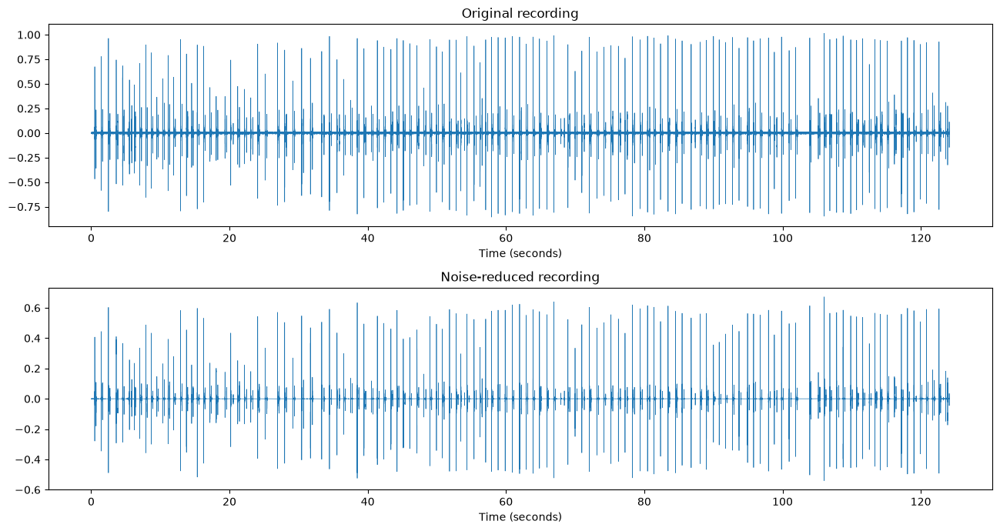

In [6]:
# Pick a sample recording for inspection.
AUDIO_FILE = audio_files[0]

y, sr = librosa.load(AUDIO_FILE, sr=SAMPLE_RATE, mono=True)
if len(y) == 0:
    raise ValueError(f"The audio file is empty: {AUDIO_FILE}")

noise_end = min(int(NOISE_SECONDS * sr), len(y))
noise_sample = y[:noise_end]

cleaned = nr.reduce_noise(
    y=y,
    sr=sr,
    y_noise=noise_sample,
    prop_decrease=NOISE_REDUCTION
)

print(f"Sample file: {AUDIO_FILE}")
print(f"Duration: {len(y) / sr:.2f} seconds")
print(f"Sample rate: {sr} Hz")

fig, axes = plt.subplots(2, 1, figsize=(13, 7))
time_axis = np.arange(len(y)) / sr
axes[0].plot(time_axis, y, linewidth=0.5)
axes[0].set_title("Original recording")
axes[0].set_xlabel("Time (seconds)")
axes[1].plot(np.arange(len(cleaned)) / sr, cleaned, linewidth=0.5)
axes[1].set_title("Noise-reduced recording")
axes[1].set_xlabel("Time (seconds)")
plt.tight_layout()
plt.show()

display(Audio(y, rate=sr))
display(Audio(cleaned, rate=sr))

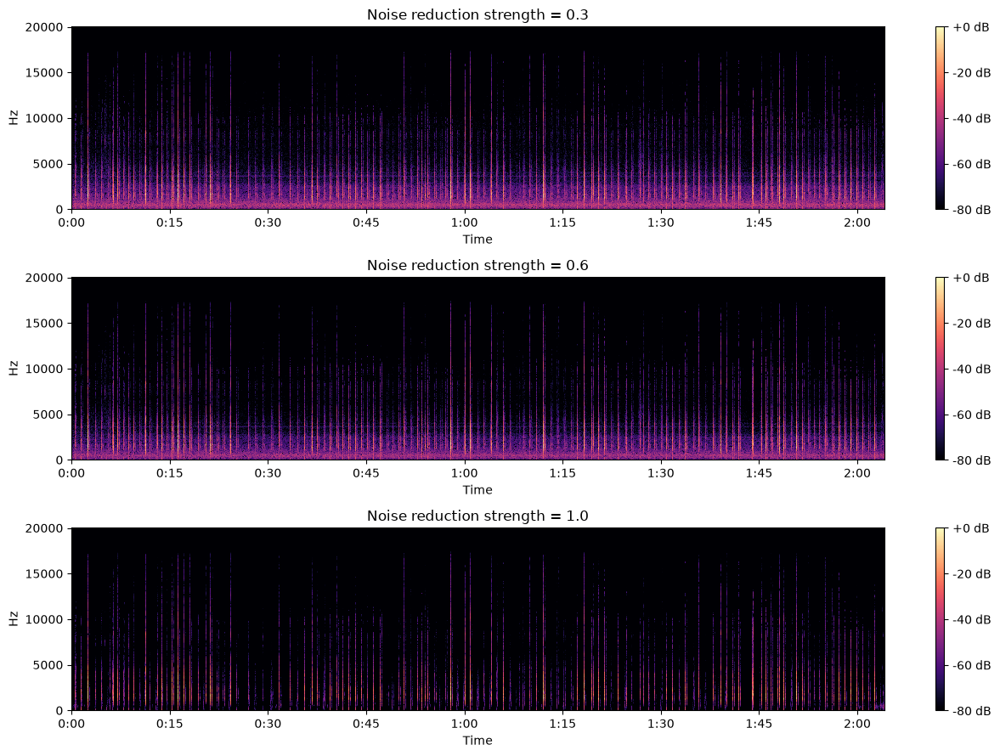

In [7]:
# Compare a few noise-reduction strengths on the sample recording.
settings = [0.3, 0.6, 1.0]
results = {}

for strength in settings:
    results[strength] = nr.reduce_noise(
        y=y,
        sr=sr,
        y_noise=noise_sample,
        prop_decrease=strength
    )

fig, axes = plt.subplots(len(settings), 1, figsize=(13, 9))
for ax, strength in zip(axes, settings):
    D = librosa.stft(results[strength], n_fft=1024, hop_length=256)
    S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)
    img = librosa.display.specshow(
        S_db, sr=sr, hop_length=256,
        x_axis="time", y_axis="hz", cmap="magma", ax=ax
    )
    ax.set_title(f"Noise reduction strength = {strength}")
    fig.colorbar(img, ax=ax, format="%+2.0f dB")
plt.tight_layout()
plt.show()

## 2. Batch-process Session 2

This is the main processing cell. It:
- reads each file in `data/session2/`;
- derives the key label from the filename stem (`A.wav` → `A`);
- detects and saves events in `dataset/session2/detected/<KEY>/`;
- saves spectrogram PNGs in `dataset/session2/spectrogram_images/<KEY>/`;
- writes `dataset/session2/manifest.csv`.

Only filenames whose stem is a single letter A–Z are processed. The script starts event numbering after any existing files for that key, so rerunning it does not overwrite already saved event files. It writes a new Session 2 manifest at the end.

In [8]:
def find_active_events(signal, sample_rate):
    # Short-time RMS energy
    frame_length = 512
    hop_length = 128

    rms = librosa.feature.rms(
        y=signal,
        frame_length=frame_length,
        hop_length=hop_length,
        center=True
    )[0]

    times = librosa.frames_to_time(
        np.arange(len(rms)),
        sr=sample_rate,
        hop_length=hop_length
    )

    # Robust threshold based on the quieter portion and the recording peak.
    noise_level = np.percentile(rms, 40)
    peak_level = np.max(rms) if len(rms) else 0.0
    threshold = max(noise_level * THRESHOLD_MULTIPLIER, peak_level * 0.04)
    active = rms > threshold

    # Merge brief gaps so downstroke/release bursts can form one event.
    max_gap_frames = max(1, int(MERGE_GAP * sample_rate / hop_length))
    active = active.copy()
    i = 0
    while i < len(active):
        if active[i]:
            i += 1
            continue
        j = i
        while j < len(active) and not active[j]:
            j += 1
        if i > 0 and j < len(active) and (j - i) <= max_gap_frames:
            active[i:j] = True
        i = j

    changes = np.diff(np.r_[False, active, False].astype(int))
    starts = np.where(changes == 1)[0]
    ends = np.where(changes == -1)[0]

    events = []
    duration = len(signal) / sample_rate
    for start_frame, end_frame in zip(starts, ends):
        start_time = max(0.0, float(times[start_frame]))
        end_time = min(duration, float(times[min(end_frame - 1, len(times) - 1)]))
        if end_time - start_time < MIN_EVENT_DURATION:
            continue

        start_sample = max(0, int((start_time - PRE_ROLL) * sample_rate))
        end_sample = min(len(signal), int((end_time + POST_ROLL) * sample_rate))
        clip = signal[start_sample:end_sample]
        if len(clip):
            events.append({
                "start": start_sample / sample_rate,
                "end": end_sample / sample_rate,
                "audio": clip
            })
    return events


def save_spectrogram(clip, sample_rate, destination):
    # Keep a consistent image size for the CNN input pipeline.
    D = librosa.stft(clip, n_fft=512, hop_length=128)
    S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)

    fig, ax = plt.subplots(figsize=(1.28, 1.28), dpi=100)
    librosa.display.specshow(
        S_db, sr=sample_rate, hop_length=128,
        x_axis=None, y_axis=None, cmap="gray", ax=ax
    )
    ax.set_axis_off()
    fig.subplots_adjust(left=0, right=1, bottom=0, top=1)
    fig.savefig(destination, dpi=100, bbox_inches=None, pad_inches=0)
    plt.close(fig)


manifest_rows = []
skipped_files = []

for audio_path in audio_files:
    label = audio_path.stem.strip().upper()

    # Require one letter A-Z in the filename, e.g. A.wav.
    if not re.fullmatch(r"[A-Z]", label):
        skipped_files.append((str(audio_path), f"filename stem '{audio_path.stem}' is not a single A-Z letter"))
        continue

    try:
        signal, file_sr = librosa.load(audio_path, sr=SAMPLE_RATE, mono=True)
        if len(signal) == 0:
            skipped_files.append((str(audio_path), "empty audio"))
            continue

        noise_end = min(int(NOISE_SECONDS * file_sr), len(signal))
        noise_sample = signal[:noise_end]
        cleaned_signal = nr.reduce_noise(
            y=signal,
            sr=file_sr,
            y_noise=noise_sample,
            prop_decrease=NOISE_REDUCTION
        )

        events = find_active_events(cleaned_signal, file_sr)
        detected_dir = DETECTED_ROOT / label
        spectrogram_dir = SPECTROGRAM_ROOT / label
        detected_dir.mkdir(parents=True, exist_ok=True)
        spectrogram_dir.mkdir(parents=True, exist_ok=True)

        existing_ids = []
        for existing in detected_dir.glob("event_*.wav"):
            match = re.fullmatch(r"event_(\d+)\.wav", existing.name)
            if match:
                existing_ids.append(int(match.group(1)))
        next_id = max(existing_ids, default=0) + 1

        print(f"{audio_path.name}: detected {len(events)} event(s)")

        for offset, event in enumerate(events):
            event_id = next_id + offset
            wav_path = detected_dir / f"event_{event_id:03d}.wav"
            png_path = spectrogram_dir / f"event_{event_id:03d}.png"

            # Do not overwrite existing event files.
            if wav_path.exists() or png_path.exists():
                raise FileExistsError(
                    f"Output already exists for {label} event {event_id}. "
                    "Move/rename the existing Session 2 outputs or choose a fresh output folder."
                )

            sf.write(wav_path, event["audio"], file_sr)
            save_spectrogram(event["audio"], file_sr, png_path)

            manifest_rows.append({
                "image_path": str(png_path).replace("\\", "/"),
                "audio_path": str(wav_path).replace("\\", "/"),
                "source_recording": audio_path.name,
                "label": label,
                "session_id": "session2",
                "start_seconds": round(event["start"], 4),
                "end_seconds": round(event["end"], 4)
            })

    except Exception as exc:
        skipped_files.append((str(audio_path), f"{type(exc).__name__}: {exc}"))

# Save manifest only for this session.
manifest_columns = [
    "image_path", "audio_path", "source_recording", "label",
    "session_id", "start_seconds", "end_seconds"
]
manifest_df = pd.DataFrame(manifest_rows, columns=manifest_columns)
manifest_df.to_csv(MANIFEST_PATH, index=False)

print("\nFinished processing Session 2.")
print(f"Saved events/spectrograms: {len(manifest_df)}")
print(f"Manifest: {MANIFEST_PATH.resolve()}")

if not manifest_df.empty:
    print("\nSamples per key:")
    display(manifest_df.groupby("label").size().reindex(list("ABCDEFGHIJKLMNOPQRSTUVWXYZ"), fill_value=0).rename("samples").to_frame())

if skipped_files:
    print("\nFiles skipped or failed:")
    for file_name, reason in skipped_files:
        print(f"- {file_name}: {reason}")

A.mp3: detected 126 event(s)
B.mp3: detected 119 event(s)
C.mp3: detected 156 event(s)
D.mp3: detected 114 event(s)
E.mp3: detected 128 event(s)
F.mp3: detected 94 event(s)
G.mp3: detected 140 event(s)
H.mp3: detected 100 event(s)
I.mp3: detected 135 event(s)
J.mp3: detected 129 event(s)
K.mp3: detected 109 event(s)
L.mp3: detected 112 event(s)
M.mp3: detected 119 event(s)
N.mp3: detected 79 event(s)
O.mp3: detected 142 event(s)
P.mp3: detected 114 event(s)
Q.mp3: detected 101 event(s)
R.mp3: detected 136 event(s)
S.mp3: detected 150 event(s)
T.mp3: detected 131 event(s)
U.mp3: detected 110 event(s)
V.mp3: detected 92 event(s)
W.mp3: detected 99 event(s)
X.mp3: detected 127 event(s)
Y.mp3: detected 85 event(s)
Z.mp3: detected 123 event(s)

Finished processing Session 2.
Saved events/spectrograms: 3070
Manifest: C:\Users\My Pc\Desktop\Code\keyboard sound detection\dataset\session2\manifest.csv

Samples per key:


,samples
label,
A,126
B,119
C,156
D,114
E,128
F,94
G,140
H,100
I,135


## 3. Verify the generated dataset

Check the manifest and listen to a few saved events before evaluating the model. Automatic detection may split a press into multiple clips or miss quiet presses, so spot-check the output.

In [ ]:
if MANIFEST_PATH.exists():
    check_df = pd.read_csv(MANIFEST_PATH)
    display(check_df.head(10))
    print("Manifest rows:", len(check_df))
    print("Labels found:", sorted(check_df["label"].dropna().unique().tolist()))

    # Listen to the first saved event if available.
    if not check_df.empty:
        sample_audio_path = Path(check_df.iloc[0]["audio_path"])
        clip, clip_sr = sf.read(sample_audio_path)
        print("Example event:", sample_audio_path)
        display(Audio(clip, rate=clip_sr))
else:
    print("Manifest has not been created yet. Run the batch-processing cell first.")